In [1]:
import os

print(os.listdir("/content"))

['.config', '.ipynb_checkpoints', 'sample_data']


In [2]:
from google.colab import files

uploaded = files.upload()

Saving dataset_tugas1_preprocessing.csv to dataset_tugas1_preprocessing.csv


In [3]:
import os

print(os.listdir("/content"))

['.config', '.ipynb_checkpoints', 'dataset_tugas1_preprocessing.csv', 'sample_data']


In [9]:
#Tahap 1 : Load Dataset
import pandas as pd

data = pd.read_csv("/content/dataset_tugas1_preprocessing.csv")

data.head()

,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
0,MH001,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,13-04-2020,NaN
1,MH002,Eka,Perempuan,Teknik Komputer,Lulus,E,2020/12/11,28.0
2,MH003,Iwan,Laki-laki,Teknik Komputer,Aktif,NaN,2021/11/21,23.0
3,MH004,Eka,Perempuan,Teknik Komputer,Aktif,D,2021/08/19,18.0
4,MH005,Joko,Perempuan,Data Science,Aktif,C,2020/01/05,26.0


In [10]:
# Tahap 2: Eksplorasi Awal (EDA)

# 1. Cek struktur dan tipe data
print("=== Struktur dan Tipe Data ===")
data.info()

# 2. Tampilkan jumlah nilai hilang per kolom
print("\n=== Jumlah Nilai Hilang ===")
print(data.isnull().sum())

# 3. Sajikan statistik deskriptif
print("\n=== Statistik Deskriptif ===")
data.describe(include="all")

=== Struktur dan Tipe Data ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99 entries, 0 to 98
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             99 non-null     object 
 1   Nama           99 non-null     object 
 2   Jenis_Kelamin  99 non-null     object 
 3   Prodi          99 non-null     object 
 4   Status         99 non-null     object 
 5   Nilai_Akhir    70 non-null     object 
 6   Tanggal_Ujian  99 non-null     object 
 7   Umur           90 non-null     float64
dtypes: float64(1), object(7)
memory usage: 6.3+ KB

=== Jumlah Nilai Hilang ===
ID                0
Nama              0
Jenis_Kelamin     0
Prodi             0
Status            0
Nilai_Akhir      29
Tanggal_Ujian     0
Umur              9
dtype: int64

=== Statistik Deskriptif ===


,ID,Nama,Jenis_Kelamin,Prodi,Status,Nilai_Akhir,Tanggal_Ujian,Umur
count,99,99,99,99,99,70,99,90.000000
unique,99,10,2,4,4,5,97,NaN
top,MH001,Eka,Laki-laki,Teknik Komputer,Cuti,C,2020/03/31,NaN
freq,1,15,50,28,29,17,2,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.366667
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.763963
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.000000


In [18]:
# Tahap 3: Menangani Missing Values

# Mengisi nilai kosong pada Nilai_Akhir dengan modus
data["Nilai_Akhir"] = data["Nilai_Akhir"].fillna(data["Nilai_Akhir"].mode()[0])

# Mengisi nilai kosong pada umur dengan median
data["Umur"] = data["Umur"].fillna(data["Umur"].median())

# Cek ulang jumlah nilai kosong
print("Jumlah nilai hilang setelah imputasi:")
print(data[["Nilai_Akhir", "Umur"]].isnull().sum())

Jumlah nilai hilang setelah imputasi:
Nilai_Akhir    0
Umur           0
dtype: int64


In [17]:
# Tahap 4: Normalisasi Format Tanggal

# Membaca data asli
data = pd.read_csv("/content/dataset_tugas1_preprocessing.csv")

# Ubah Tanggal_Ujian menjadi format datetime
data["Tanggal_Ujian"] = pd.to_datetime(
    data["Tanggal_Ujian"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

# Cek hasil
print("Tipe data Tanggal_Ujian:")
print(data["Tanggal_Ujian"].dtype)

print("\nJumlah tanggal yang gagal dikonversi (NaT):")
print(data["Tanggal_Ujian"].isnull().sum())

print("\nContoh hasil konversi:")
print(data["Tanggal_Ujian"].head(10))

Tipe data Tanggal_Ujian:
datetime64[ns]

Jumlah tanggal yang gagal dikonversi (NaT):
0

Contoh hasil konversi:
0   2020-04-13
1   2020-12-11
2   2021-11-21
3   2021-08-19
4   2020-01-05
5   2021-10-15
6   2020-01-15
7   2020-09-16
8   2021-02-06
9   2020-02-12
Name: Tanggal_Ujian, dtype: datetime64[ns]


In [19]:
# Tahap 5: Encoding Label

from sklearn.preprocessing import LabelEncoder

# Buat objek Label Encoder
le = LabelEncoder()

# Kolom yang akan di-encoding
kolom_kategorikal = [
    "Nama",
    "Jenis_Kelamin",
    "Prodi",
    "Status",
    "Nilai_Akhir"
]

# Melakukan Label Encoding
for kolom in kolom_kategorikal:
    data[kolom] = le.fit_transform(data[kolom].astype(str))

# Tampilkan 5 data pertama setelah encoding
print("Data setelah Label Encoding:")
print(data.head())

Data setelah Label Encoding:
      ID  Nama  Jenis_Kelamin  Prodi  Status  Nilai_Akhir Tanggal_Ujian  Umur
0  MH001     8              0      3       0            2    2020-04-13  23.0
1  MH002     4              1      3       3            4    2020-12-11  28.0
2  MH003     8              0      3       0            2    2021-11-21  23.0
3  MH004     4              1      3       0            3    2021-08-19  18.0
4  MH005     9              1      0       0            2    2020-01-05  26.0


In [20]:
# Tahap 6: Split Data

from sklearn.model_selection import train_test_split

# Bagi data menjadi data latih dan data uji (80% - 20%)
data_train, data_test = train_test_split(
    data,
    test_size=0.2,
    random_state=42
)

# Cek jumlah data
print("Jumlah data keseluruhan :", len(data))
print("Jumlah data latih      :", len(data_train))
print("Jumlah data uji        :", len(data_test))

Jumlah data keseluruhan : 99
Jumlah data latih      : 79
Jumlah data uji        : 20


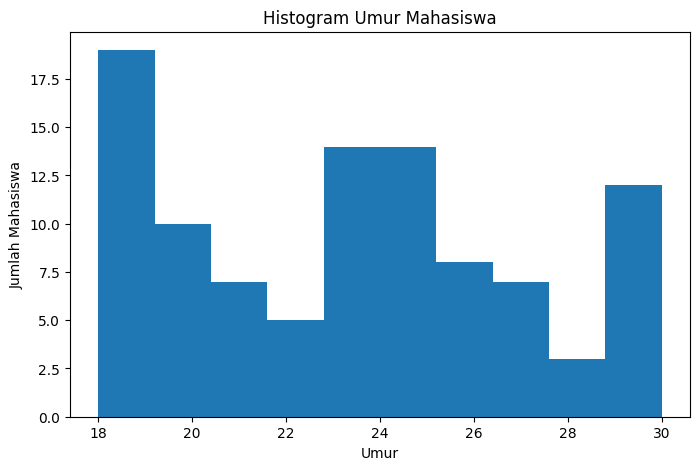

In [21]:
# Tahap 7: Visualisasi
# 1. Buat histogram untuk kolom umur

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(data["Umur"], bins=10)
plt.title("Histogram Umur Mahasiswa")
plt.xlabel("Umur")
plt.ylabel("Jumlah Mahasiswa")
plt.show()

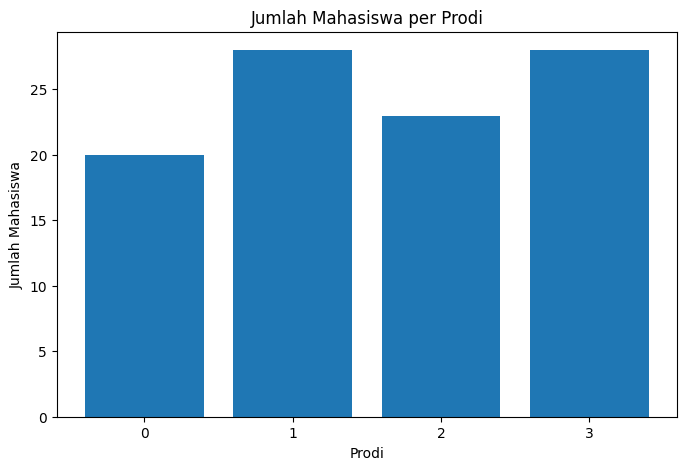

In [22]:
# 2. Buat grafik batang jumlah mahasiswa per prodi

prodi_count = data["Prodi"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(prodi_count.index.astype(str), prodi_count.values)
plt.title("Jumlah Mahasiswa per Prodi")
plt.xlabel("Prodi")
plt.ylabel("Jumlah Mahasiswa")
plt.show()